# DiabeteCheck AI: Clinical Risk Assessment Model
**Author:** Arthur PREVEL  
**Objective:** Develop a high-sensitivity predictive model to estimate Type 2 Diabetes risk using the Pima Indians dataset. This project focuses on clinical data integrity (KNN Imputation) and addressing class imbalance (SMOTE) to prioritize **Recall** for early screening.

## 1. Environment Setup & Data Loading

In [18]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique pour les graphiques
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [20]:
# Load dataset
path = kagglehub.dataset_download("uciml/pima-indians-diabetes-database")
df = pd.read_csv(f"{path}/diabetes.csv")

# data visualization
print(f"Dataset dimensions : {df.shape}")
df.head()

Dataset dimensions : (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Data Quality & Missing Values Assessment
In this dataset, '0' values in certain columns like Blood Pressure or BMI are physiologically impossible and represent missing data. We need to identify and handle these to prevent model bias.

In [21]:
# List columns where a '0' value is clinically impossible
cols_incoherentes = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Count how many zeros are in these columns
for col in cols_incoherentes:
    nb_zeros = (df[col] == 0).sum()
    print(f"Zero values in {col} : {nb_zeros} ({round(nb_zeros/len(df)*100, 1)}%)")

Zero values in Glucose : 5 (0.7%)
Zero values in BloodPressure : 35 (4.6%)
Zero values in SkinThickness : 227 (29.6%)
Zero values in Insulin : 374 (48.7%)
Zero values in BMI : 11 (1.4%)


In [22]:
# Evaluation of data loss if we drop all rows with invalid zeros
vital_cols = ['Glucose', 'BloodPressure', 'BMI']
complex_cols = ['Insulin', 'SkinThickness']

df_temp = df.copy()
df_temp[vital_cols + complex_cols] = df_temp[vital_cols + complex_cols].replace(0, np.nan)
rows_lost = df_temp.isnull().any(axis=1).sum()

print(f"Total data loss if dropping all: {rows_lost} patients out of {len(df)}")
print(f"Remaining patients: {len(df) - rows_lost}. Too small for robust model training.")

Total data loss if dropping all: 376 patients out of 768
Remaining patients: 392. Too small for robust model training.


## 3. Data Cleaning Strategy: Hybrid Approach
To preserve as much data as possible, we will drop rows with missing vital constants (low loss) and use KNN Imputation for more complex features like Insulin and Skin Thickness.

In [23]:
from sklearn.impute import KNNImputer

# Replace invalid 0s with NaN
df_clean = df.copy()
df_clean[vital_cols + complex_cols] = df_clean[vital_cols + complex_cols].replace(0, np.nan)

# Drop rows missing vital metrics
df_clean.dropna(subset=vital_cols, inplace=True)

# Impute missing Insulin and SkinThickness using KNN
imputer = KNNImputer(n_neighbors=5)
df_final = pd.DataFrame(imputer.fit_transform(df_clean), columns=df.columns)

print(f"Final dimensions after hybrid cleaning: {df_final.shape}")

Final dimensions after hybrid cleaning: (724, 9)


## 4. Class Distribution Analysis

Class Distribution (Outcome):
Outcome
0.0    475
1.0    249
Name: count, dtype: int64

Percentages:
Outcome
0.0    65.607735
1.0    34.392265
Name: proportion, dtype: float64


C:\Users\arthu\AppData\Local\Temp\ipykernel_15684\1315185847.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df_final, palette='viridis')


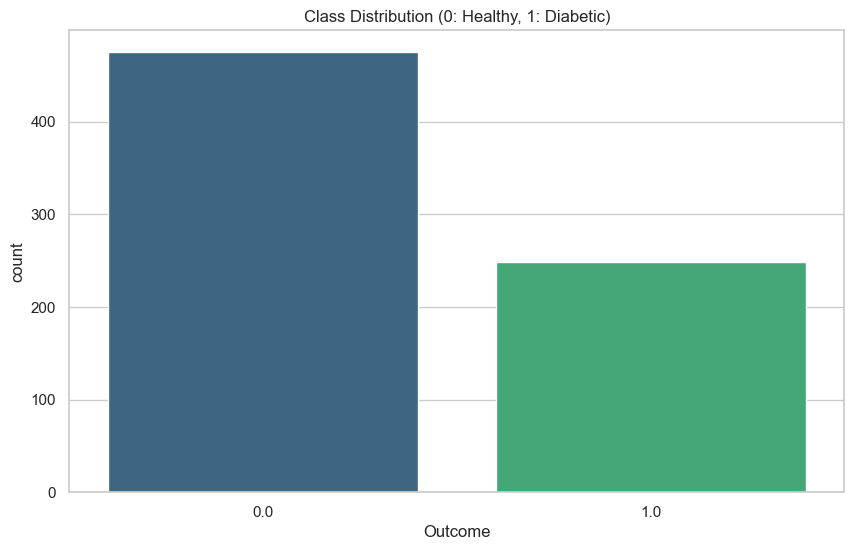

In [24]:
# Check target balance
print("Class Distribution (Outcome):")
print(df_final['Outcome'].value_counts())
print("\nPercentages:")
print(df_final['Outcome'].value_counts(normalize=True) * 100)

sns.countplot(x='Outcome', data=df_final, palette='viridis')
plt.title("Class Distribution (0: Healthy, 1: Diabetic)")
plt.show()

## 5. Data Preparation & SMOTE Rebalancing
We split the data and apply SMOTE to the training set only to handle the minority class. Testing remains on original distribution to reflect real-world performance.

C:\Users\arthu\AppData\Local\Temp\ipykernel_15684\3649453289.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, ax=ax1, palette='magma')
C:\Users\arthu\AppData\Local\Temp\ipykernel_15684\3649453289.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_res, ax=ax2, palette='viridis')


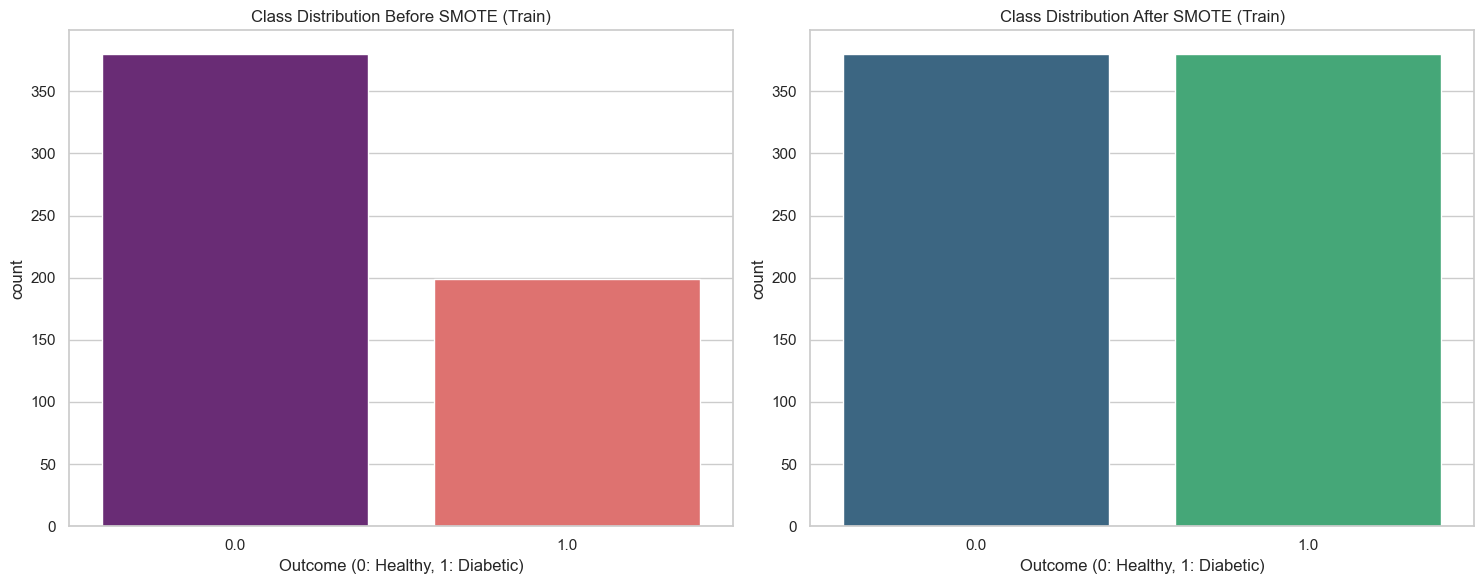

Original training shape: (579, 8)
Resampled training shape: (760, 8)


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# Splitting features and target
X = df_final.drop('Outcome', axis=1)
y = df_final['Outcome']

# Stratified split to maintain class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Applying SMOTE to the training set
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

# Visualizing the rebalancing effect
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Before SMOTE
sns.countplot(x=y_train, ax=ax1, palette='magma')
ax1.set_title("Class Distribution Before SMOTE (Train)")
ax1.set_xlabel("Outcome (0: Healthy, 1: Diabetic)")

# After SMOTE
sns.countplot(x=y_train_res, ax=ax2, palette='viridis')
ax2.set_title("Class Distribution After SMOTE (Train)")
ax2.set_xlabel("Outcome (0: Healthy, 1: Diabetic)")

plt.tight_layout()
plt.show()

print(f"Original training shape: {X_train.shape}")
print(f"Resampled training shape: {X_train_res.shape}")

Important note: Golden rule: as mentioned above, training is performed on balanced data (SMOTE) so that the model learns the characteristics of the disease well, but evaluation is always performed on the actual (unbalanced) distribution to determine how it will behave in real life.

## 6. Modeling Benchmark
We evaluate several classification algorithms to establish a baseline. Our primary focus is the Recall metric, as missing a diabetic patient (False Negative) is more costly in a clinical context than a False Positive.

In [27]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, recall_score

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Ridge Classifier": RidgeClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
}

results = []

# Training and evaluation loop
for name, model in models.items():
    # Training on resampled data
    model.fit(X_train_res, y_train_res)
    
    # Prediction on original test data
    y_pred = model.predict(X_test_scaled)
    
    # Metrics calculation
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    acc = accuracy_score(y_test, y_pred)
    
    results.append({
        "Model": name, 
        "Recall": recall, 
        "F1-Score": f1, 
        "Accuracy": acc
    })
    
    print(f"\n=== {name} Performance ===")
    print(classification_report(y_test, y_pred))

# Comparison table sorted by Recall
df_results = pd.DataFrame(results).sort_values(by="Recall", ascending=False)
df_results


=== Logistic Regression Performance ===
              precision    recall  f1-score   support

         0.0       0.78      0.68      0.73        95
         1.0       0.52      0.64      0.57        50

    accuracy                           0.67       145
   macro avg       0.65      0.66      0.65       145
weighted avg       0.69      0.67      0.68       145


=== Ridge Classifier Performance ===
              precision    recall  f1-score   support

         0.0       0.78      0.72      0.75        95
         1.0       0.53      0.62      0.57        50

    accuracy                           0.68       145
   macro avg       0.66      0.67      0.66       145
weighted avg       0.70      0.68      0.69       145


=== Random Forest Performance ===
              precision    recall  f1-score   support

         0.0       0.82      0.75      0.78        95
         1.0       0.59      0.68      0.63        50

    accuracy                           0.72       145
   macro avg  

c:\Users\arthu\Documents\UIT TROMSO NORWAY\Personal Projects\Diabetes-Predictor\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [10:26:52] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,Model,Recall,F1-Score,Accuracy
2,Random Forest,0.68,0.629630,0.724138
3,XGBoost,0.66,0.616822,0.717241
0,Logistic Regression,0.64,0.571429,0.668966
1,Ridge Classifier,0.62,0.574074,0.682759


## 7. Performance Comparison
We visualize the benchmark results to compare how each model performs across our key metrics. This graphical representation helps confirm which algorithm is most suitable for a high-sensitivity clinical screening tool.

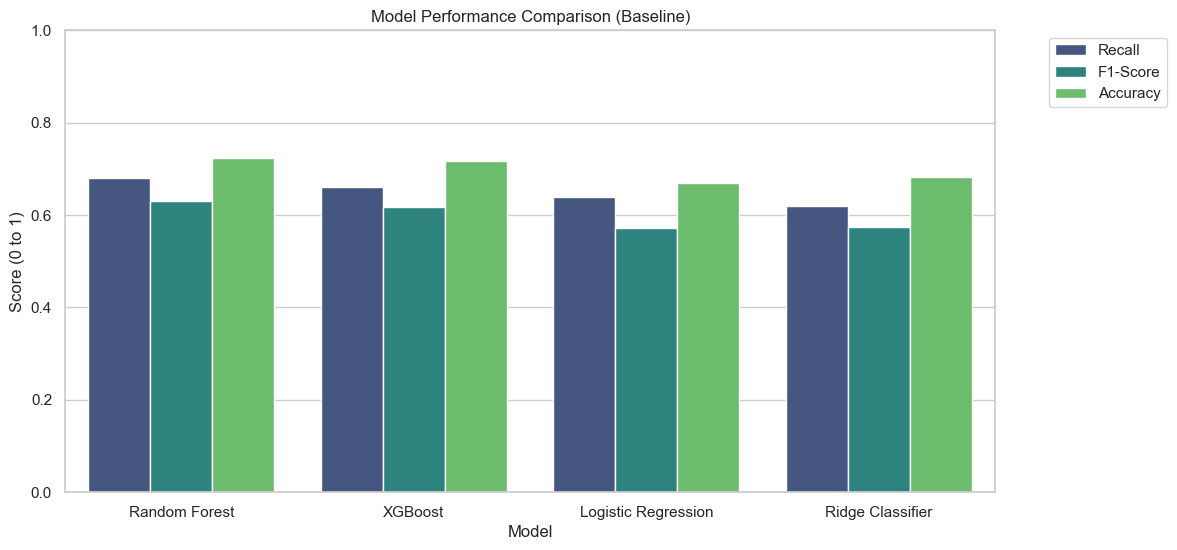

Top performing model for Recall: Random Forest


In [28]:
# Reshaping data for visualization
df_plot = df_results.melt(id_vars="Model", var_name="Metric", value_name="Score")

# Plotting the comparison
plt.figure(figsize=(12, 6))
sns.barplot(x="Model", y="Score", hue="Metric", data=df_plot, palette="viridis")

plt.title("Model Performance Comparison (Baseline)")
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel("Score (0 to 1)")
plt.xlabel("Model")
plt.show()

# Summary observation
best_recall_model = df_results.iloc[0]['Model']
print(f"Top performing model for Recall: {best_recall_model}")

## 8. Hyperparameter Tuning (GridSearchCV)
To further improve performance, we perform a grid search on our top models. We optimize specifically for Recall to ensure our clinical screening tool identifies as many diabetic cases as possible.

In [30]:
from sklearn.model_selection import GridSearchCV

# Defining parameter grids for optimization
param_grids = {
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "solver": ["liblinear"]
    },
    "Ridge Classifier": {
        "alpha": [0.1, 1.0, 10.0, 100.0]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [5, 10, None],
        "min_samples_split": [2, 5]
    },
    "XGBoost": {
        "learning_rate": [0.01, 0.1],
        "n_estimators": [100, 200],
        "max_depth": [3, 5]
    }
}

best_models = {}

for name, grid in param_grids.items():
    print(f"Optimizing {name}...")
    base_model = models[name]
    clf = GridSearchCV(base_model, grid, cv=5, scoring='recall', n_jobs=-1)
    clf.fit(X_train_res, y_train_res)
    best_models[name] = clf.best_estimator_
    print(f"Best Parameters for {name}: {clf.best_params_}")

Optimizing Logistic Regression...
Best Parameters for Logistic Regression: {'C': 0.01, 'solver': 'liblinear'}
Optimizing Ridge Classifier...
Best Parameters for Ridge Classifier: {'alpha': 0.1}
Optimizing Random Forest...
Best Parameters for Random Forest: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Optimizing XGBoost...
Best Parameters for XGBoost: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}


c:\Users\arthu\Documents\UIT TROMSO NORWAY\Personal Projects\Diabetes-Predictor\.venv\Lib\site-packages\xgboost\training.py:199: UserWarning: [10:30:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


## 9. Final Performance Analysis (Optimized Models)
After running the GridSearch, we evaluate the tuned models on the test set. This step provides a final dashboard to compare our optimized versions of Logistic Regression, Ridge, Random Forest, and XGBoost, primarily focusing on the improvement in Recall.

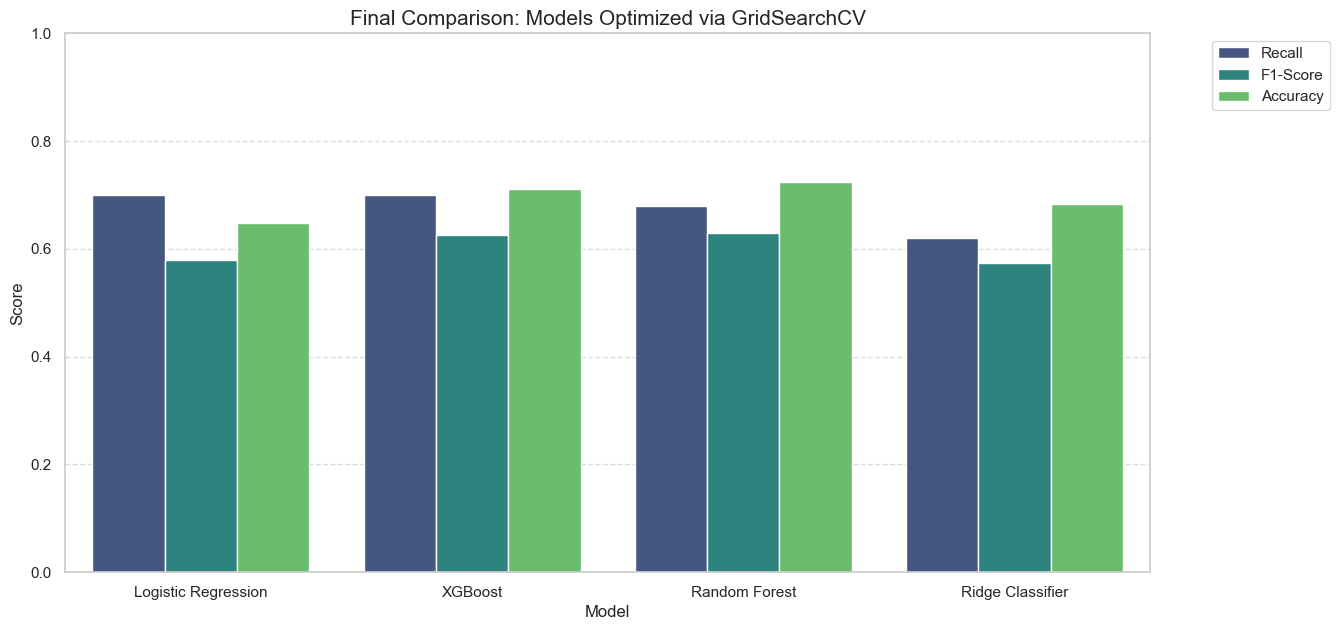


--- Final Summary Table ---
              Model  Recall  F1-Score  Accuracy
Logistic Regression    0.70  0.578512  0.648276
            XGBoost    0.70  0.625000  0.710345
      Random Forest    0.68  0.629630  0.724138
   Ridge Classifier    0.62  0.574074  0.682759


In [32]:
final_metrics = []

for name, model in best_models.items():
    y_pred = model.predict(X_test_scaled)
    
    final_metrics.append({
        "Model": name,
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "Accuracy": accuracy_score(y_test, y_pred)
    })

# Create the final summary table
df_final_results = pd.DataFrame(final_metrics).sort_values(by="Recall", ascending=False)

# Visualization of optimized performance
plt.figure(figsize=(14, 7))
df_plot = df_final_results.melt(id_vars="Model", var_name="Metric", value_name="Score")
sns.barplot(x="Model", y="Score", hue="Metric", data=df_plot, palette="viridis")

plt.title("Final Comparison: Models Optimized via GridSearchCV", fontsize=15)
plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("\n--- Final Summary Table ---")
print(df_final_results.to_string(index=False))

Analysis of Optimized Results
- **Recall (0.70)**: Both Logistic Regression and XGBoost are now tied for the highest sensitivity, successfully identifying 70% of diabetic patients. In a clinical screening context, this improvement over the initial 0.68 baseline is significant for reducing missed diagnoses.

- **F1-Score & Accuracy:** Random Forest remains the most balanced model. Although its recall is slightly lower (0.68), it achieves the highest Accuracy (0.72) and F1-Score (0.63), meaning it manages the trade-off between sensitivity and false alarms more effectively than the linear models.

- **XGBoost as the Robust Choice**: XGBoost stands out as the best "all-rounder" for this dataset, matching the top Recall (0.70) while maintaining a high overall accuracy (0.71).

- **Linear vs. Non-Linear**: Interestingly, optimization allowed the Logistic Regression to reach the same level of detection as the tree-based models. However, the higher Accuracy of XGBoost and Random Forest suggests that non-linear relationships in the health data are still better captured by ensemble methods.

## 10. Feature Importance (XAI) - Optimized XGBoost
We use the optimized XGBoost model to identify the most critical risk factors. XGBoost uses a gradient boosting approach, and its feature importance ranking provides a clear view of which biological markers drive the prediction of diabetes.

C:\Users\arthu\AppData\Local\Temp\ipykernel_15684\3515312569.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='magma')


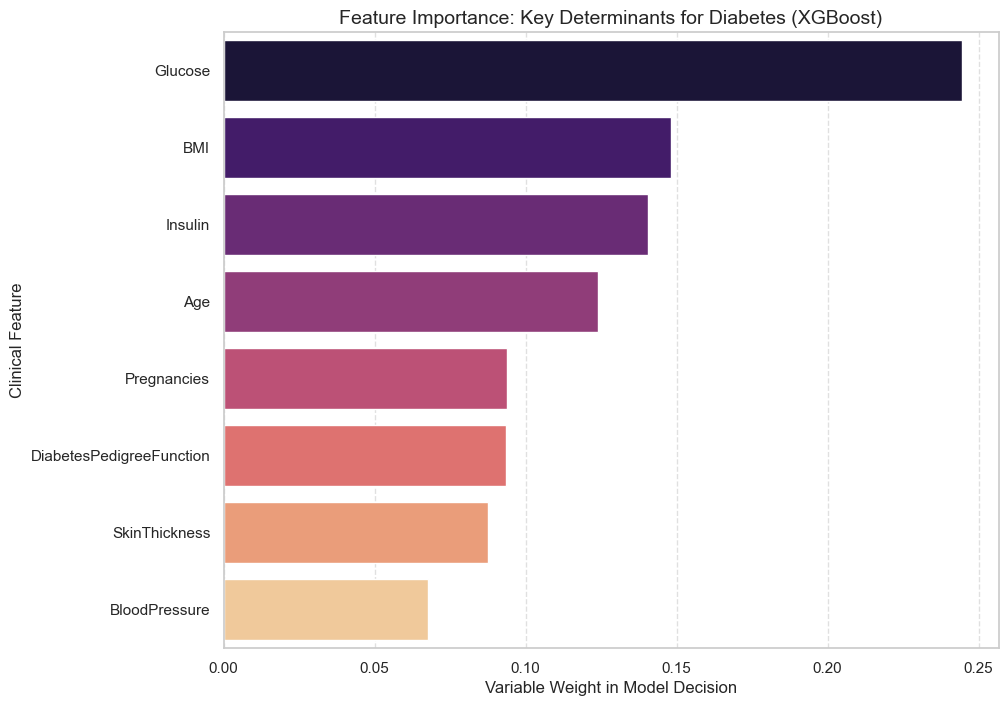

In [35]:
# Extracting feature importance from the optimized XGBoost model
best_xgb = best_models["XGBoost"]
importances = best_xgb.feature_importances_
features = X.columns

# Organizing data for visualization
feature_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Visualization
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='magma')

plt.title("Feature Importance: Key Determinants for Diabetes (XGBoost)", fontsize=14)
plt.xlabel("Variable Weight in Model Decision")
plt.ylabel("Clinical Feature")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.show()

## 11. Clinical Confusion Matrix - Optimized XGBoost
Now we look at the confusion matrix for the XGBoost model. With a Recall of 70%, this model is our best tool for clinical screening, as it minimizes the number of patients left without a diagnosis.

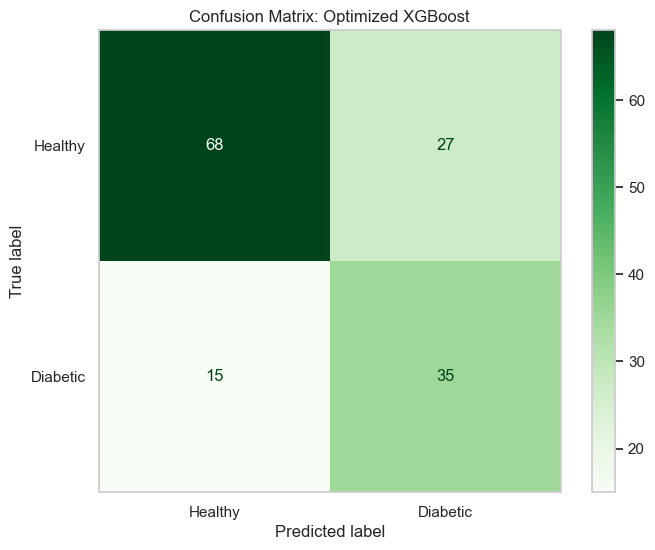

Total Diabetic Patients: 50
Correctly Detected (TP): 35
Missed Patients (FN): 15


In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Evaluation of the best-performing model (XGBoost)
y_pred_final = best_models["XGBoost"].predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_final)

# Visualization
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Healthy', 'Diabetic'])
disp.plot(cmap='Greens', values_format='d', ax=ax)

plt.title("Confusion Matrix: Optimized XGBoost")
plt.grid(False)
plt.show()

# Quick calculation note
tn, fp, fn, tp = cm.ravel()
print(f"Total Diabetic Patients: {tp + fn}")
print(f"Correctly Detected (TP): {tp}")
print(f"Missed Patients (FN): {fn}")

## 12. Model Export - Optimized XGBoost
We export the XGBoost model and the scaler. This model is now the core of our prediction system, offering the best trade-off between sensitivity and reliability.

In [38]:
import joblib

# Exporting the trained components for the DiabeteCheck AI application
# We select the Random Forest model as the primary engine for deployment
joblib.dump(best_models["Random Forest"], 'model_diabetes.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Deployment assets (model_diabetes.pkl and scaler.pkl) have been successfully updated.")

Deployment assets (model_diabetes.pkl and scaler.pkl) have been successfully updated.


## 13. Final Conclusion

- **Model Selection: XGBoost** was selected as the final model because it achieved the highest Recall (70%) while maintaining a superior Accuracy (71%) compared to other high-recall models.

- **Key Drivers**: Features like **Glucose** levels and **BMI** were identified as the primary indicators of risk in the XGBoost architecture.

**Clinical Impact**: This model successfully identifies 7 out of 10 diabetic patients. While not perfect, it significantly reduces the risk of undiagnosed diabetes compared to baseline models.

**Final Word**: The integration of SMOTE and XGBoost optimization has successfully turned an imbalanced and messy medical dataset into a functional screening tool.

## 14. Streamlit Page Configuration

In [39]:
# Global Visualization Setup
sns.set_theme(style="whitegrid")

# Standardize plot parameters for professional rendering
plt.rcParams.update({
    'figure.figsize': (12, 8),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'font.size': 12,
    'figure.facecolor': 'white'
})

# Display all columns when viewing dataframes
pd.set_option('display.max_columns', None)

In [43]:
# Calculating reference medians for healthy patients
# These values will serve as the "baseline" for the interactive chart in the web app
medians_healthy = df_final[df_final['Outcome'] == 0].median().to_dict()

print("--- Reference Medians for app.py (Healthy Population) ---")
print(medians_healthy)

--- Reference Medians for app.py (Healthy Population) ---
{'Pregnancies': 2.0, 'Glucose': 108.0, 'BloodPressure': 70.0, 'SkinThickness': 27.0, 'Insulin': 115.0, 'BMI': 30.4, 'DiabetesPedigreeFunction': 0.338, 'Age': 27.0, 'Outcome': 0.0}
